# Data Splitting — train / val / test

Splits the labelled corpus `dataset_v2.parquet` into **70 / 10 / 20** train / val / test using a single scikit-learn splitter, `StratifiedGroupKFold`:

- **stratified** on `label` → class ratios are the same in every split;
- **grouped** on `topic_id` → a topic never appears in two splits, so same-topic documents cannot leak from train into test, and every `ai_revised` row stays in the same split as its source human cluster.

The splitter produces 10 folds of ~10% each: fold 0 → val, folds 1–2 → test, the rest → train.

Result: `data/train_val_test_split.json` (doc_id lists per split). Nothing else is written — `dataset_v2.parquet` and the frozen `splits_v2.*` artifacts stay untouched.

In [1]:
import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

from aitextd import plots

SEED = 42

# kernels may start in the repo root or inside notebooks/
DATA_DIR = Path("../data" if Path.cwd().name == "notebooks" else "data")

In [2]:
df = pd.read_parquet(DATA_DIR / "dataset_v2.parquet")
print(f"{len(df):,} documents")
df["label"].value_counts()

33,687 documents


label
human         20964
ai            10534
ai_revised     2189
Name: count, dtype: int64

In [3]:
folds = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(
    df, y=df["label"], groups=df["topic_id"]
))

FOLD_NAMES = ["val", "test", "test"] + ["train"] * 7  # 10 folds of ~10% -> 70/10/20

df["split"] = ""
for fold_no, (_, members) in enumerate(folds):
    df.loc[members, "split"] = FOLD_NAMES[fold_no]

In [4]:
assert (df["split"] != "").all(), "every document must get exactly one split"
for a, b in combinations(("train", "val", "test"), 2):
    for column in ("doc_id", "topic_id"):
        in_a = set(df.loc[df["split"] == a, column])
        in_b = set(df.loc[df["split"] == b, column])
        assert in_a.isdisjoint(in_b), f"{column} shared between {a} and {b}: {len(in_a & in_b)}"

display(pd.crosstab(df["split"], df["label"], margins=True))
display(pd.crosstab(df["split"], df["label"], normalize="index").round(3))

label,ai,ai_revised,human,All
split,,,,
test,2107,437,4194,6738
train,7373,1533,14674,23580
val,1054,219,2096,3369
All,10534,2189,20964,33687


label,ai,ai_revised,human
split,,,
test,0.313,0.065,0.622
train,0.313,0.065,0.622
val,0.313,0.065,0.622


<Axes: title={'left': 'Canonical 70/10/20 split — documents per label'}>

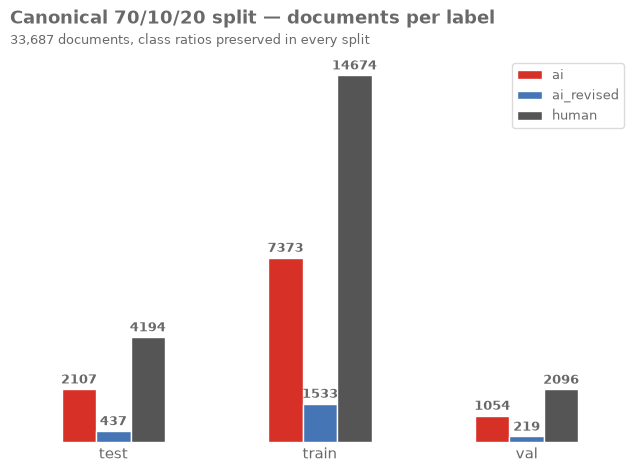

In [5]:
plots.grouped_counts(
    pd.crosstab(df["split"], df["label"]), "Canonical 70/10/20 split — documents per label"
)

In [6]:
artifact = {
    "seed": SEED,
    "splitter": "StratifiedGroupKFold(n_splits=10, shuffle=True)",
    "stratify": "label",
    "groups": "topic_id",
    "counts": df["split"].value_counts().to_dict(),
    **{
        name: df.loc[df["split"] == name, "doc_id"].tolist()
        for name in ("train", "val", "test")
    },
}

out_path = DATA_DIR / "train_val_test_split.json"
out_path.write_text(json.dumps(artifact), encoding="utf-8")
print(f"saved -> {out_path} ({out_path.stat().st_size / 1e6:.1f} MB)")

saved -> ../data/train_val_test_split.json (1.2 MB)


## Using the splits elsewhere

`doc_id` is a stable content hash, so the split survives row reordering. The
shared loader lives in `aitextd.splits` and is what every other notebook uses:

```python
from aitextd import splits

train_df, val_df, test_df = splits.canonical_frames()
```

The raw artifact is `data/train_val_test_split.json` (doc_id lists per split).